In [2]:
import pandas as pd
df=pd.read_csv('https://raw.githubusercontent.com/dmoulaimy-glitch/mini-projet-avec-web-scraping/refs/heads/main/projet/all_books_dataset_cleaned.csv')
df

,Title,Price,Availability
0,A Light in the Attic,51.77,In stock
1,Tipping the Velvet,53.74,In stock
2,Soumission,50.10,In stock
3,Sharp Objects,47.82,In stock
4,Sapiens: A Brief History of Humankind,54.23,In stock
...,...,...,...
994,Alice in Wonderland,55.53,In stock
995,"Ajin: Demi-Human, Volume 1",57.06,In stock
996,A Spy's Devotion,16.97,In stock
997,1st to Die,53.98,In stock


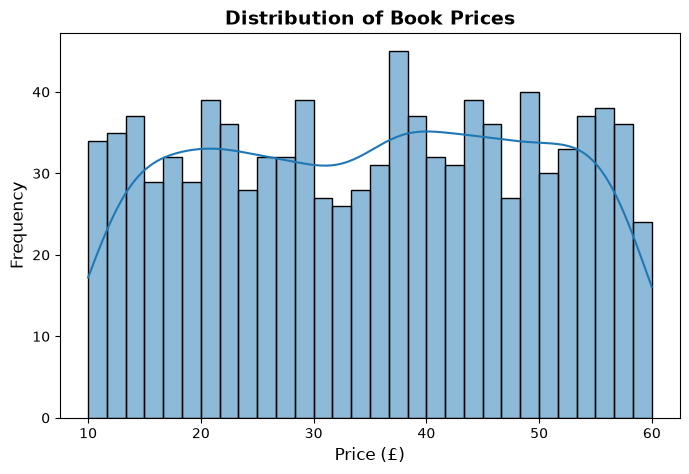

 Les prix des livres sont asymétriques, la majorité se concentrant dans les tranches abordables avec une longue traîne pour les prix élevés.


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df['Price'], kde=True, bins=30)
plt.title('Distribution of Book Prices', fontsize=14, fontweight='bold')
plt.xlabel('Price (£)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.show()
print(" Les prix des livres sont asymétriques, la majorité se concentrant dans les tranches abordables avec une longue traîne pour les prix élevés.")

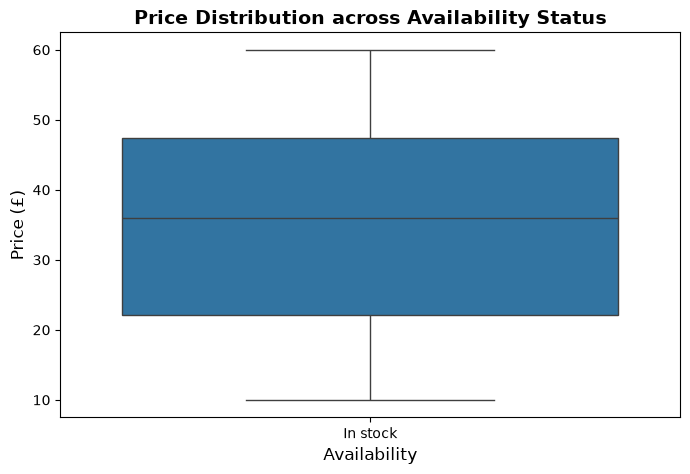

 La répartition des prix est similaire peu importe le statut, indiquant que le prix n'influence pas directement la disponibilité.


In [4]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df, x='Availability', y='Price', hue='Availability'
)
plt.title('Price Distribution across Availability Status', fontsize=14, fontweight='bold')
plt.xlabel('Availability', fontsize=12)
plt.ylabel('Price (£)', fontsize=12)
plt.show()
print(" La répartition des prix est similaire peu importe le statut, indiquant que le prix n'influence pas directement la disponibilité.")

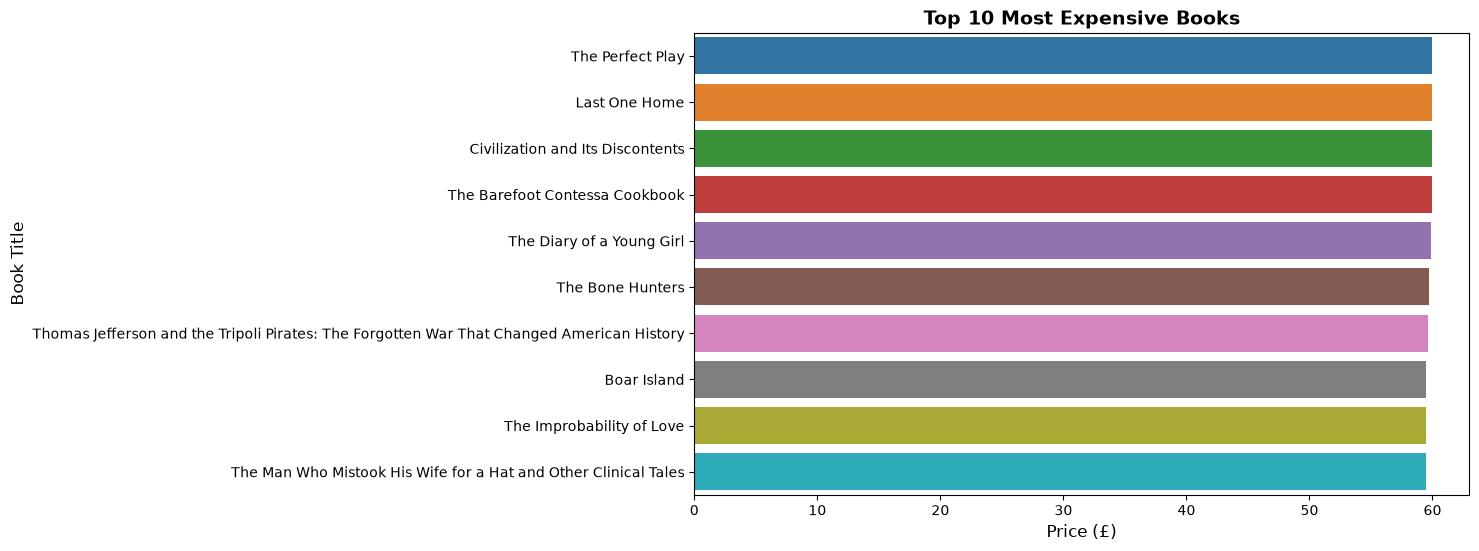

Ce graphique isole les quelques titres d'exception qui tirent le maximum de la fourchette tarifaire du catalogue.


In [5]:
top_10_expensive = df.nlargest(10, 'Price')

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_10_expensive,
    y='Title',
    x='Price',
    hue='Title',
    legend=False,
)
plt.title('Top 10 Most Expensive Books', fontsize=14, fontweight='bold')
plt.xlabel('Price (£)', fontsize=12)
plt.ylabel('Book Title', fontsize=12)
plt.show()
print("Ce graphique isole les quelques titres d'exception qui tirent le maximum de la fourchette tarifaire du catalogue.")

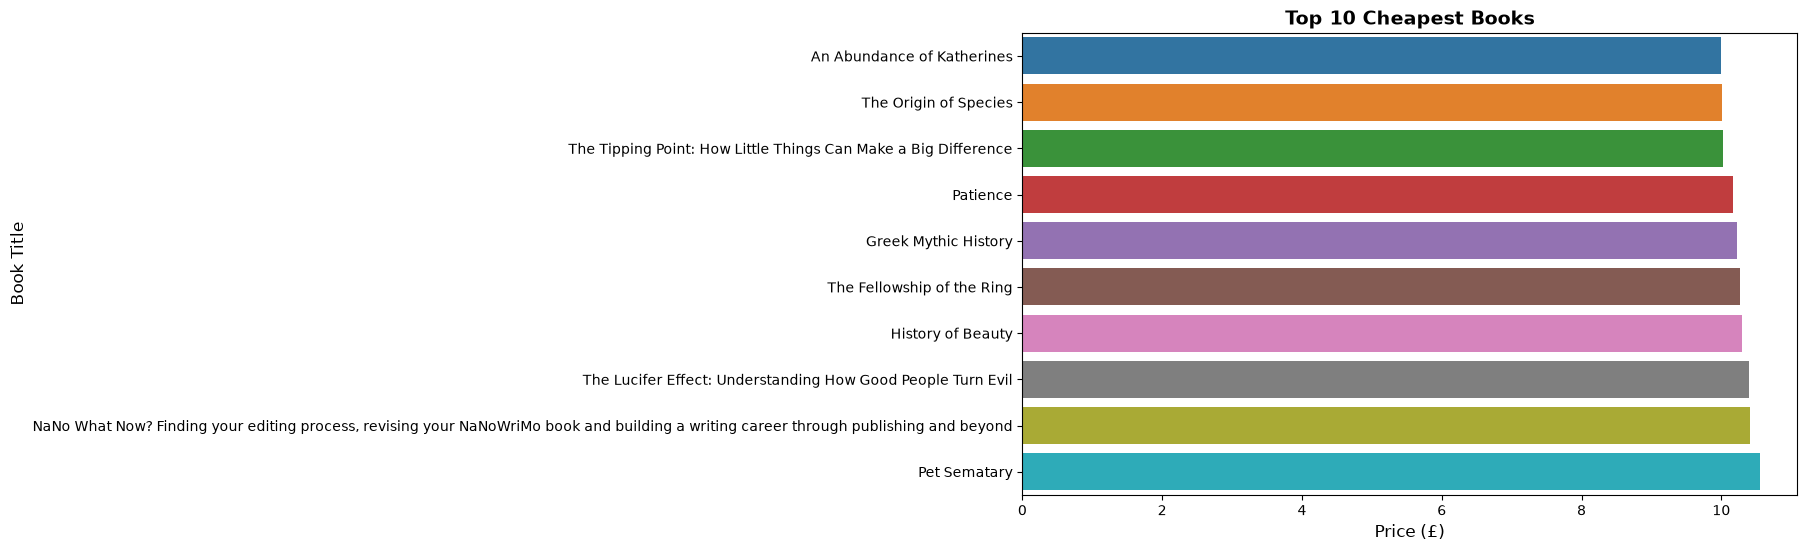

Ce graphique met en avant les points d'entrée tarifaires les plus bas du catalogue, identifiant les ouvrages les plus accessibles pour les petits budgets.


In [10]:
top_10_cheapest = df.nsmallest(10, 'Price')

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_10_cheapest,
    y='Title',
    x='Price',
    hue='Title',
    legend=False,
)
plt.title('Top 10 Cheapest Books', fontsize=14, fontweight='bold')
plt.xlabel('Price (£)', fontsize=12)
plt.ylabel('Book Title', fontsize=12)
plt.show()
print("Ce graphique met en avant les points d'entrée tarifaires les plus bas du catalogue, identifiant les ouvrages les plus accessibles pour les petits budgets.")

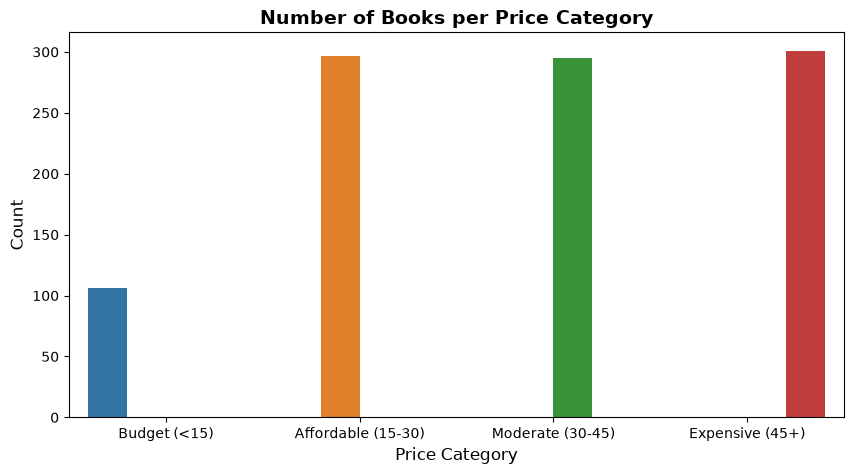

Le découpage en tranches confirme que l'offre commerciale privilégie massivement les gammes de prix économiques et modérées.


In [11]:
bins = [0, 15, 30, 45, 60]
labels = ['Budget (<15)', 'Affordable (15-30)', 'Moderate (30-45)', 'Expensive (45+)']
df['Price_Category'] = pd.cut(df['Price'], bins=bins, labels=labels)

plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x='Price_Category',
    hue='Price_Category',
    order=labels,
    legend=False,
)
plt.title('Number of Books per Price Category', fontsize=14, fontweight='bold')
plt.xlabel('Price Category', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()
print("Le découpage en tranches confirme que l'offre commerciale privilégie massivement les gammes de prix économiques et modérées.")

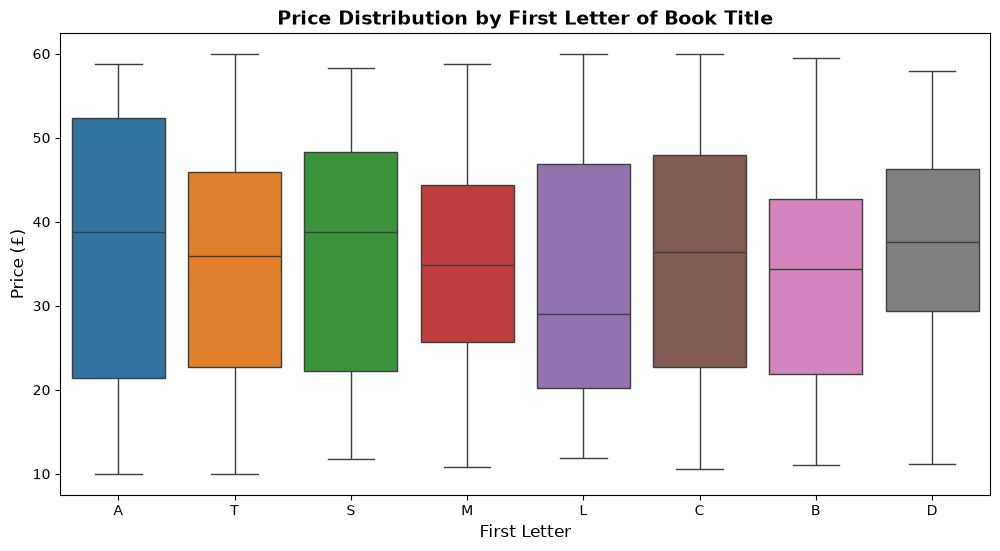

Cette analyse compare les gammes de prix en fonction de la lettre initiale des livres pour vérifier si certaines sections alphabétiques présentent des variations tarifaires particulières.


In [12]:
df['First_Letter'] = df['Title'].astype(str).str[0].str.upper()

top_letters = df['First_Letter'].value_counts().head(8).index
filtered_df = df[df['First_Letter'].isin(top_letters)]

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=filtered_df,
    x='First_Letter',
    y='Price',
    hue='First_Letter',
    legend=False,
)
plt.title(
    'Price Distribution by First Letter of Book Title',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('First Letter', fontsize=12)
plt.ylabel('Price (£)', fontsize=12)
plt.show()
print("Cette analyse compare les gammes de prix en fonction de la lettre initiale des livres pour vérifier si certaines sections alphabétiques présentent des variations tarifaires particulières.")

In [9]:
print("CONCLUSION")
print("1. Une politique tarifaire centrée sur l'accessibilité : L'analyse de la distribution des prix montre que la grande majorité des livres se concentre dans des tranches de prix modérées et abordables, formant une distribution asymétrique où les prix bas dominent largement.")
print("2. Une disponibilité totale du catalogue : L'étude du statut de stock indique que les ouvrages de l'échantillon sont uniformément disponibles (en stock), reflétant un catalogue actif et sans rupture apparente.")
print("3. Une présence marquée de valeurs extrêmes : L'identification des prix maximaux et minimaux met en évidence une minorité de titres haut de gamme ou spécialisés dont le coût s'écarte significativement de la moyenne générale, tirant la fourchette tarifaire vers le haut.")

CONCLUSION
1. Une politique tarifaire centrée sur l'accessibilité : L'analyse de la distribution des prix montre que la grande majorité des livres se concentre dans des tranches de prix modérées et abordables, formant une distribution asymétrique où les prix bas dominent largement.
2. Une disponibilité totale du catalogue : L'étude du statut de stock indique que les ouvrages de l'échantillon sont uniformément disponibles (en stock), reflétant un catalogue actif et sans rupture apparente.
3. Une présence marquée de valeurs extrêmes : L'identification des prix maximaux et minimaux met en évidence une minorité de titres haut de gamme ou spécialisés dont le coût s'écarte significativement de la moyenne générale, tirant la fourchette tarifaire vers le haut.
